In [1]:
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from metrics import apk

DATA = Path("data")
con = duckdb.connect()
con.execute("SET enable_progress_bar = false")
con.execute(f"CREATE VIEW tx AS SELECT * FROM '{(DATA / 'sample_transactions.parquet').as_posix()}'")

def fill(items, filler, k=12):
    out = list(items[:k])
    for f in filler:
        if len(out) >= k: break
        if f not in out: out.append(f)
    return out

rows = []
for t in range(12, -1, -1):
    lo, hi = t + 1, t + 8
    lab = con.execute(f"SELECT customer_id, LIST(DISTINCT article_id) AS b FROM tx WHERE w = {t} GROUP BY customer_id").df()
    actual = {c: list(b) for c, b in zip(lab["customer_id"], lab["b"])}

    top2 = con.execute(f"""SELECT article_id FROM tx WHERE w BETWEEN {lo} AND {lo + 1}
        GROUP BY article_id ORDER BY COUNT(DISTINCT customer_id) DESC, article_id LIMIT 12""").df()["article_id"].tolist()

    pdf = con.execute(f"""
        SELECT customer_id, LIST(article_id ORDER BY last_buy DESC, n DESC, article_id) AS items
        FROM (SELECT customer_id, article_id, MAX(t_dat) AS last_buy, COUNT(*) AS n
              FROM tx WHERE w BETWEEN {lo} AND {hi} GROUP BY customer_id, article_id)
        GROUP BY customer_id""").df()
    past = {c: list(i) for c, i in zip(pdf["customer_id"], pdf["items"])}

    prt = con.execute(f"""
        WITH b AS (SELECT DISTINCT customer_id, t_dat, article_id FROM tx WHERE w BETWEEN {lo} AND {hi}),
        p AS (SELECT x.article_id AS item, y.article_id AS partner, COUNT(*) AS n
              FROM b x JOIN b y ON x.customer_id = y.customer_id AND x.t_dat = y.t_dat
                                AND x.article_id <> y.article_id GROUP BY ALL),
        r AS (SELECT *, ROW_NUMBER() OVER (PARTITION BY item ORDER BY n DESC, partner) AS rk FROM p)
        SELECT item, LIST(partner ORDER BY rk) AS partners FROM r WHERE rk <= 3 GROUP BY item""").df()
    partners = {i: list(p) for i, p in zip(prt["item"], prt["partners"])}

    def with_partners(items):
        out = list(items)
        for it in items:
            for q in partners.get(it, []):
                if q not in out: out.append(q)
        return out

    new_share = con.execute(f"""
        SELECT AVG(CASE WHEN a.first_w = {t} THEN 1.0 ELSE 0 END)
        FROM (SELECT DISTINCT article_id FROM tx WHERE w = {t}) x
        JOIN (SELECT article_id, MAX(w) AS first_w FROM tx WHERE w >= {t} GROUP BY article_id) a USING (article_id)
    """).fetchone()[0]

    rows.append({
        "w": t,
        "week_start": con.execute(f"SELECT MIN(t_dat) FROM tx WHERE w = {t}").fetchone()[0],
        "buyers": len(actual),
        "pct_with_history": round(100 * np.mean([c in past for c in actual]), 1),
        "pct_new_items": round(100 * new_share, 1),
        "popularity": round(np.mean([apk(actual[c], top2) for c in actual]), 5),
        "classic_best": round(np.mean([apk(actual[c], fill(with_partners(past.get(c, [])), top2)) for c in actual]), 5),
    })

drift = pd.DataFrame(rows)
print(drift.to_string(index=False))

 w week_start  buyers  pct_with_history  pct_new_items  popularity  classic_best
12 2020-06-24   22895              60.9            7.2     0.00228       0.02066
11 2020-07-01   17061              65.4            6.0     0.00271       0.02320
10 2020-07-08   15269              66.9            6.4     0.00179       0.02044
 9 2020-07-15   15455              66.8            6.1     0.00321       0.01936
 8 2020-07-22   16023              65.9            6.7     0.00417       0.02022
 7 2020-07-29   16789              66.3            6.1     0.00385       0.01903
 6 2020-08-05   14976              66.8            5.7     0.00304       0.02032
 5 2020-08-12   14208              68.2            6.6     0.00354       0.02353
 4 2020-08-19   14361              64.8            8.3     0.00280       0.02045
 3 2020-08-26   15930              61.8            8.4     0.00644       0.02024
 2 2020-09-02   15220              61.4            9.5     0.00695       0.02492
 1 2020-09-09   14471       

 w week_start  popularity  popularity_alert  classic_best  classic_best_alert
12 2020-06-24     0.00228             False       0.02066               False
11 2020-07-01     0.00271             False       0.02320               False
10 2020-07-08     0.00179             False       0.02044               False
 9 2020-07-15     0.00321             False       0.01936               False
 8 2020-07-22     0.00417             False       0.02022               False
 7 2020-07-29     0.00385             False       0.01903               False
 6 2020-08-05     0.00304             False       0.02032               False
 5 2020-08-12     0.00354             False       0.02353               False
 4 2020-08-19     0.00280              True       0.02045               False
 3 2020-08-26     0.00644             False       0.02024               False
 2 2020-09-02     0.00695             False       0.02492               False
 1 2020-09-09     0.00686             False       0.02554       

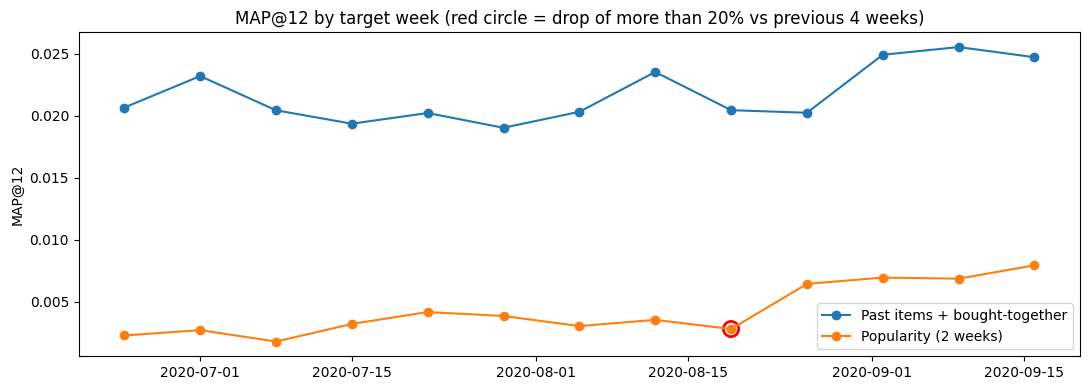

In [2]:
d = drift.sort_values("w", ascending=False).reset_index(drop=True)

for col in ["popularity", "classic_best"]:
    base = d[col].shift(1).rolling(4).mean()
    d[f"{col}_alert"] = d[col] < 0.8 * base

print(d[["w", "week_start", "popularity", "popularity_alert", "classic_best", "classic_best_alert"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(d["week_start"], d["classic_best"], marker="o", label="Past items + bought-together")
ax.plot(d["week_start"], d["popularity"], marker="o", label="Popularity (2 weeks)")
for col in ["popularity", "classic_best"]:
    flagged = d[d[f"{col}_alert"]]
    ax.scatter(flagged["week_start"], flagged[col], s=120, facecolors="none", edgecolors="red", linewidths=2)
ax.set_title("MAP@12 by target week (red circle = drop of more than 20% vs previous 4 weeks)")
ax.set_ylabel("MAP@12")
ax.legend()
plt.tight_layout()
plt.savefig("reports_drift.png", dpi=120)
plt.show()

## Weekly drift check

To see how stable things would be in production, I re-ran the same recipe for 13 target weeks, from late June to the final week of September 2020. Each week only used the 8 weeks of history before it. I left out LightGBM because rebuilding its features takes about 2 minutes per week, and tracked the two simple methods instead.

![Weekly MAP@12](reports_drift.png)

Popularity was very unstable. Its best week scored 4.4 times its worst (0.00794 vs 0.00179). It roughly doubled from late August onward. My guess is that a new season or the end of the summer sale changed what people were buying, but I can't confirm that from this data. The personal method (past items plus bought-together) was much steadier, between 0.01903 and 0.02554, and it beat popularity in all 13 weeks.

This also changed how I read my own results. My validation and test weeks happen to be among the best weeks. The test score for the classic method (0.02472) is about 14% above its 13-week average (0.02174). So the numbers I report are probably on the high side for a typical week. That's worth knowing before anyone promises a number to a business.

I added a simple alert: flag any week that scores more than 20% below the average of the previous 4 weeks. It fired once, for popularity in the week of 19 August, right before what sold shifted. It never fired for the personal method. In production, I'd run this every week and also track simpler signals that don't need waiting for sales, like the number of buyers and the share of brand-new items. Thirteen weeks is too short to tune the alert threshold properly.